# Counting Challenge — AI solution (YOLO11 instance segmentation)

**Author:** Ramesh K

Counts the items (screws, bolts, nuts, washers) in every image and overlays an instance mask on each counted item with a fine-tuned deep-learning model.

## Approach
| Stage | What happens |
|---|---|
| 1. Pseudo-labels | The dataset has no annotations. The classical pipeline (see `../Non_AI`) is run on the **training images only** and only its *confident* instances are kept as labels: isolated single items, and nuts/washers whose mask is the region nearest to their own hole (Voronoi split, limited to one nut radius). Uncertain blobs (touching screws) are painted with background colour so they are neither positives nor false negatives. |
| 2. Tiling | Photos are 12 MP and the items are small, so every image is scaled to 2400 px and cut into 640×640 tiles with overlap. |
| 3. Training | `yolo11s-seg` (COCO-pretrained, generic — no screw/nut data) is fine-tuned on the tiles, single class `item`, with flip, rotation and colour augmentation. |
| 4. Tiled inference | Each full image is predicted tile by tile. Detections cut by an inner tile edge are dropped (the 160 px overlap guarantees the item is complete in the neighbouring tile) and the remaining duplicates are removed by mask overlap, so nothing is counted twice. |
| 5. Evaluation | One image of every object group is **held out** (never used for labels or training) and accuracy is reported on those and on all images. |

**Runtime:** ~20–30 min on a Kaggle T4 GPU, ~1 h on a GTX 1650 (Settings → Accelerator → GPU T4, Internet on). On a CPU-only machine it runs a 1-epoch smoke test.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("ultralytics") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])

In [2]:
import os
import glob
import time
import random
import shutil

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy import ndimage as ndi
import ultralytics
from ultralytics import YOLO

print("ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| CUDA", torch.cuda.is_available())

ultralytics 8.3.253 | torch 2.4.1+cu118 | CUDA True


## Configuration

In [3]:
def find_data_dir():
    for p in [os.environ.get("DATA_DIR", "-"), "../../data/CountingChallenge", "../data/CountingChallenge",
              "data/CountingChallenge", "/content/CountingChallenge"]:
        if glob.glob(os.path.join(p, "**", "*.jpg"), recursive=True):
            return p
    hits = glob.glob("/kaggle/input/**/Screws_2024_07_15", recursive=True)
    return os.path.dirname(hits[0]) if hits else None


def find_ground_truth():
    hits = ["../ground_truth.csv"] + glob.glob("/kaggle/input/**/ground_truth.csv", recursive=True)
    return next((p for p in hits if os.path.exists(p)), None)


DATA_DIR = find_data_dir()
assert DATA_DIR, "Dataset not found - set DATA_DIR to the folder that contains the images"
GT_CSV = find_ground_truth()

ON_GPU = torch.cuda.is_available()
WORK_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "work"
OUT_DIR = os.path.join(WORK_DIR, "outputs")
DS_DIR = os.path.join(WORK_DIR, "dataset")

LONG_SIDE = 2400
TILE = 640
STRIDE = 480
SEED = 0
EPOCHS = int(os.environ.get("EPOCHS", 40 if ON_GPU else 1))
BATCH = int(os.environ.get("BATCH", 16 if ON_GPU else 4))
BASE_MODEL = "yolo11s-seg.pt"

TEST_IMAGES = {"20240713_193135", "20240713_193659", "20240713_193907",
               "20240713_194316", "20240713_194630", "img6"}

random.seed(SEED)
np.random.seed(SEED)
os.makedirs(OUT_DIR, exist_ok=True)

IMAGES = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.jpg"), recursive=True))
stem = lambda p: os.path.splitext(os.path.basename(p))[0]
TRAIN = [p for p in IMAGES if stem(p) not in TEST_IMAGES]
TEST = [p for p in IMAGES if stem(p) in TEST_IMAGES]
print(DATA_DIR, "|", len(TRAIN), "train images,", len(TEST), "held-out test images | GT:", GT_CSV)

../../data/CountingChallenge | 19 train images, 6 held-out test images | GT: ../ground_truth.csv


## Step 1 — Pseudo-labels from the classical pipeline
Same pre-processing as the Non-AI notebook. An instance is **confident** if it is an isolated blob of single-item size, or a nut/washer separated by its own hole.

In [4]:
def load_image(path, long_side=LONG_SIDE):
    im = cv2.imread(path)
    s = min(1.0, long_side / max(im.shape[:2]))
    return cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)


def _poly_terms(x, y):
    return [np.ones_like(x), x, y, x * x, x * y, y * y, x ** 3, y ** 3, x * x * y, x * y * y]


def darkness_map(bgr):
    g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
    small = cv2.resize(g, None, fx=0.1, fy=0.1, interpolation=cv2.INTER_AREA)
    _, bg_mask = cv2.threshold(small.astype(np.uint8), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    bg_mask = cv2.erode(bg_mask, np.ones((5, 5), np.uint8)) > 0
    h, w = small.shape
    yy, xx = np.mgrid[0:h, 0:w]
    A = np.stack(_poly_terms(xx[bg_mask] / w, yy[bg_mask] / h), 1)
    coef, *_ = np.linalg.lstsq(A, small[bg_mask], rcond=None)
    H, W = g.shape
    YY, XX = np.mgrid[0:H, 0:W]
    background = sum(c * t for c, t in zip(coef, _poly_terms(XX / W, YY / H)))
    return np.clip(1 - g / background, 0, 1)


def binarize(bgr):
    d8 = (darkness_map(bgr) * 255).astype(np.uint8)
    _, b = cv2.threshold(d8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return cv2.morphologyEx(b, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))

In [5]:
def unit_area(areas):
    med = np.median(areas)
    for _ in range(3):
        sel = areas[(areas > 0.6 * med) & (areas < 1.5 * med)]
        if len(sel) == 0:
            break
        med = np.median(sel)
    return med


def find_round_holes(binary):
    cnts, hier = cv2.findContours(binary, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
    holes = []
    if hier is None:
        return holes
    for c, h in zip(cnts, hier[0]):
        if h[3] < 0:
            continue
        a = cv2.contourArea(c)
        if a < 15:
            continue
        per = cv2.arcLength(c, True)
        circularity = 4 * np.pi * a / (per * per + 1e-6)
        if circularity <= 0.7:
            continue
        m = cv2.moments(c)
        holes.append((a, (m["m10"] / m["m00"], m["m01"] / m["m00"])))
    return holes


def split_blob(mask, n, seeds=None):
    if n <= 1:
        return [mask]
    if seeds is None:
        ys, xs = np.nonzero(mask)
        pts = np.stack([xs, ys], 1).astype(np.float32)
        crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 0.5)
        cv2.setRNGSeed(SEED)
        _, _, seeds = cv2.kmeans(pts, n, None, crit, 3, cv2.KMEANS_PP_CENTERS)
    markers = np.zeros(mask.shape, np.int32)
    for k, (x, y) in enumerate(seeds):
        cv2.circle(markers, (int(round(x)), int(round(y))), 2, k + 1, -1)
    markers[mask == 0] = len(seeds) + 1
    dist = cv2.distanceTransform(mask, cv2.DIST_L2, 5)
    relief = cv2.normalize(-dist, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    ws = cv2.watershed(cv2.cvtColor(relief, cv2.COLOR_GRAY2BGR), markers)
    return [((ws == k + 1) & (mask > 0)).astype(np.uint8) for k in range(len(seeds))]


def nearest_seed_map(shape, seeds):
    no_seed = np.ones(shape, bool)
    seed_id = np.zeros(shape, np.int32)
    for k, (x, y) in enumerate(seeds):
        yy, xx = int(round(y)), int(round(x))
        no_seed[yy, xx] = False
        seed_id[yy, xx] = k
    dist, (iy, ix) = ndi.distance_transform_edt(no_seed, return_indices=True)
    return seed_id[iy, ix], dist

In [6]:
def classical_instances(bgr):
    binary = binarize(bgr)
    H, W = binary.shape
    filled = ndi.binary_fill_holes(binary > 0).astype(np.uint8) * 255
    n, labels, stats, _ = cv2.connectedComponentsWithStats(filled, 8)
    areas = stats[1:, 4].astype(float)
    unit = unit_area(areas[areas > 40])

    holes = find_round_holes(binary)
    ring_mode = False
    singles = [i + 1 for i in range(n - 1) if 0.6 * unit < areas[i] < 1.5 * unit]
    if holes and singles:
        hmed = np.median([a for a, _ in holes])
        holes = [h for h in holes if 0.4 * hmed < h[0] < 2.2 * hmed and hmed > 0.03 * unit]
        with_hole = {labels[int(y), int(x)] for _, (x, y) in holes}
        ring_mode = np.mean([s in with_hole for s in singles]) > 0.7

    if ring_mode:
        centres = [c for _, c in holes]
        owner, dist = nearest_seed_map(binary.shape, centres)
        cutoff = 1.25 * np.sqrt(unit / np.pi)
        seeds_of = {}
        for k, (x, y) in enumerate(centres):
            seeds_of.setdefault(labels[int(y), int(x)], []).append(k)

    confident, uncertain = [], np.zeros((H, W), np.uint8)
    for i in range(1, n):
        x, y, w, h, a = stats[i]
        mask = (labels == i).astype(np.uint8)
        if a < 0.25 * unit or x == 0 or y == 0 or x + w >= W or y + h >= H:
            uncertain |= mask
            continue
        if ring_mode:
            ks = seeds_of.get(i, [])
            sl = (slice(y, y + h), slice(x, x + w))
            for k in ks:
                m = np.zeros_like(mask)
                m[sl] = (mask[sl] > 0) & (owner[sl] == k) & (dist[sl] <= cutoff)
                confident.append(m)
            if ks:
                leftover = mask.copy()
                for m in confident[-len(ks):]:
                    leftover[m > 0] = 0
                if leftover.sum() > 0.5 * unit:
                    uncertain |= cv2.morphologyEx(leftover, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
            else:
                uncertain |= mask
        elif 0.6 * unit < a < 1.5 * unit:
            confident.append(mask)
        else:
            uncertain |= mask
    return confident, uncertain, binary

In [7]:
def mask_to_polygon(mask):
    cs, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cs:
        return None
    c = max(cs, key=cv2.contourArea)
    c = cv2.approxPolyDP(c, 1.0, True)
    return c.reshape(-1, 2) if len(c) >= 3 else None


def tile_origins(length):
    if length <= TILE:
        return [0]
    xs = list(range(0, length - TILE, STRIDE)) + [length - TILE]
    return sorted(set(xs))


if os.path.exists(DS_DIR):
    shutil.rmtree(DS_DIR)
for split in ["train", "val"]:
    os.makedirs(os.path.join(DS_DIR, "images", split), exist_ok=True)
    os.makedirs(os.path.join(DS_DIR, "labels", split), exist_ok=True)

stats_rows = []
t0 = time.time()
for path in TRAIN:
    im = load_image(path)
    confident, uncertain, binary = classical_instances(im)
    background = np.median(im[binary == 0], axis=0).astype(np.uint8)
    painted = im.copy()
    painted[cv2.dilate(uncertain, np.ones((7, 7), np.uint8)) > 0] = background
    H, W = im.shape[:2]
    areas = [m.sum() for m in confident]
    n_tiles = 0
    for y0 in tile_origins(H):
        for x0 in tile_origins(W):
            tile = painted[y0:y0 + TILE, x0:x0 + TILE].copy()
            lines = []
            for m, full in zip(confident, areas):
                part = m[y0:y0 + TILE, x0:x0 + TILE]
                a = part.sum()
                if a == 0:
                    continue
                if a < 0.35 * full:
                    tile[cv2.dilate(part, np.ones((7, 7), np.uint8)) > 0] = background
                    continue
                poly = mask_to_polygon(part)
                if poly is None:
                    continue
                th, tw = part.shape
                lines.append("0 " + " ".join(f"{x / tw:.5f} {y / th:.5f}" for x, y in poly))
            split = "val" if random.random() < 0.15 else "train"
            name = f"{stem(path)}_{y0}_{x0}"
            cv2.imwrite(os.path.join(DS_DIR, "images", split, name + ".jpg"), tile)
            with open(os.path.join(DS_DIR, "labels", split, name + ".txt"), "w") as f:
                f.write("\n".join(lines))
            n_tiles += 1
    stats_rows.append({"image": stem(path), "confident_labels": len(confident), "tiles": n_tiles})
    print(f"{stem(path):22s} labels={len(confident):4d} tiles={n_tiles}")

with open(os.path.join(DS_DIR, "data.yaml"), "w") as f:
    f.write(f"path: {os.path.abspath(DS_DIR)}\ntrain: images/train\nval: images/val\nnames:\n  0: item\n")
print(f"\n{sum(r['confident_labels'] for r in stats_rows)} labelled instances, "
      f"{sum(r['tiles'] for r in stats_rows)} tiles in {time.time() - t0:.0f}s")

20240713_192951        labels=  13 tiles=20


20240713_193650        labels=   3 tiles=20


20240713_193831        labels=  73 tiles=20


20240713_193839        labels=  72 tiles=20


20240713_194200        labels=  41 tiles=20


20240713_194206        labels=  44 tiles=20


... (9 outputs left out)

img2                   labels=  43 tiles=6


img3                   labels=  43 tiles=8


img4                   labels=  43 tiles=8


img5                   labels=  43 tiles=8

2075 labelled instances, 304 tiles in 80s


### Label check — a few training tiles with their pseudo-label polygons

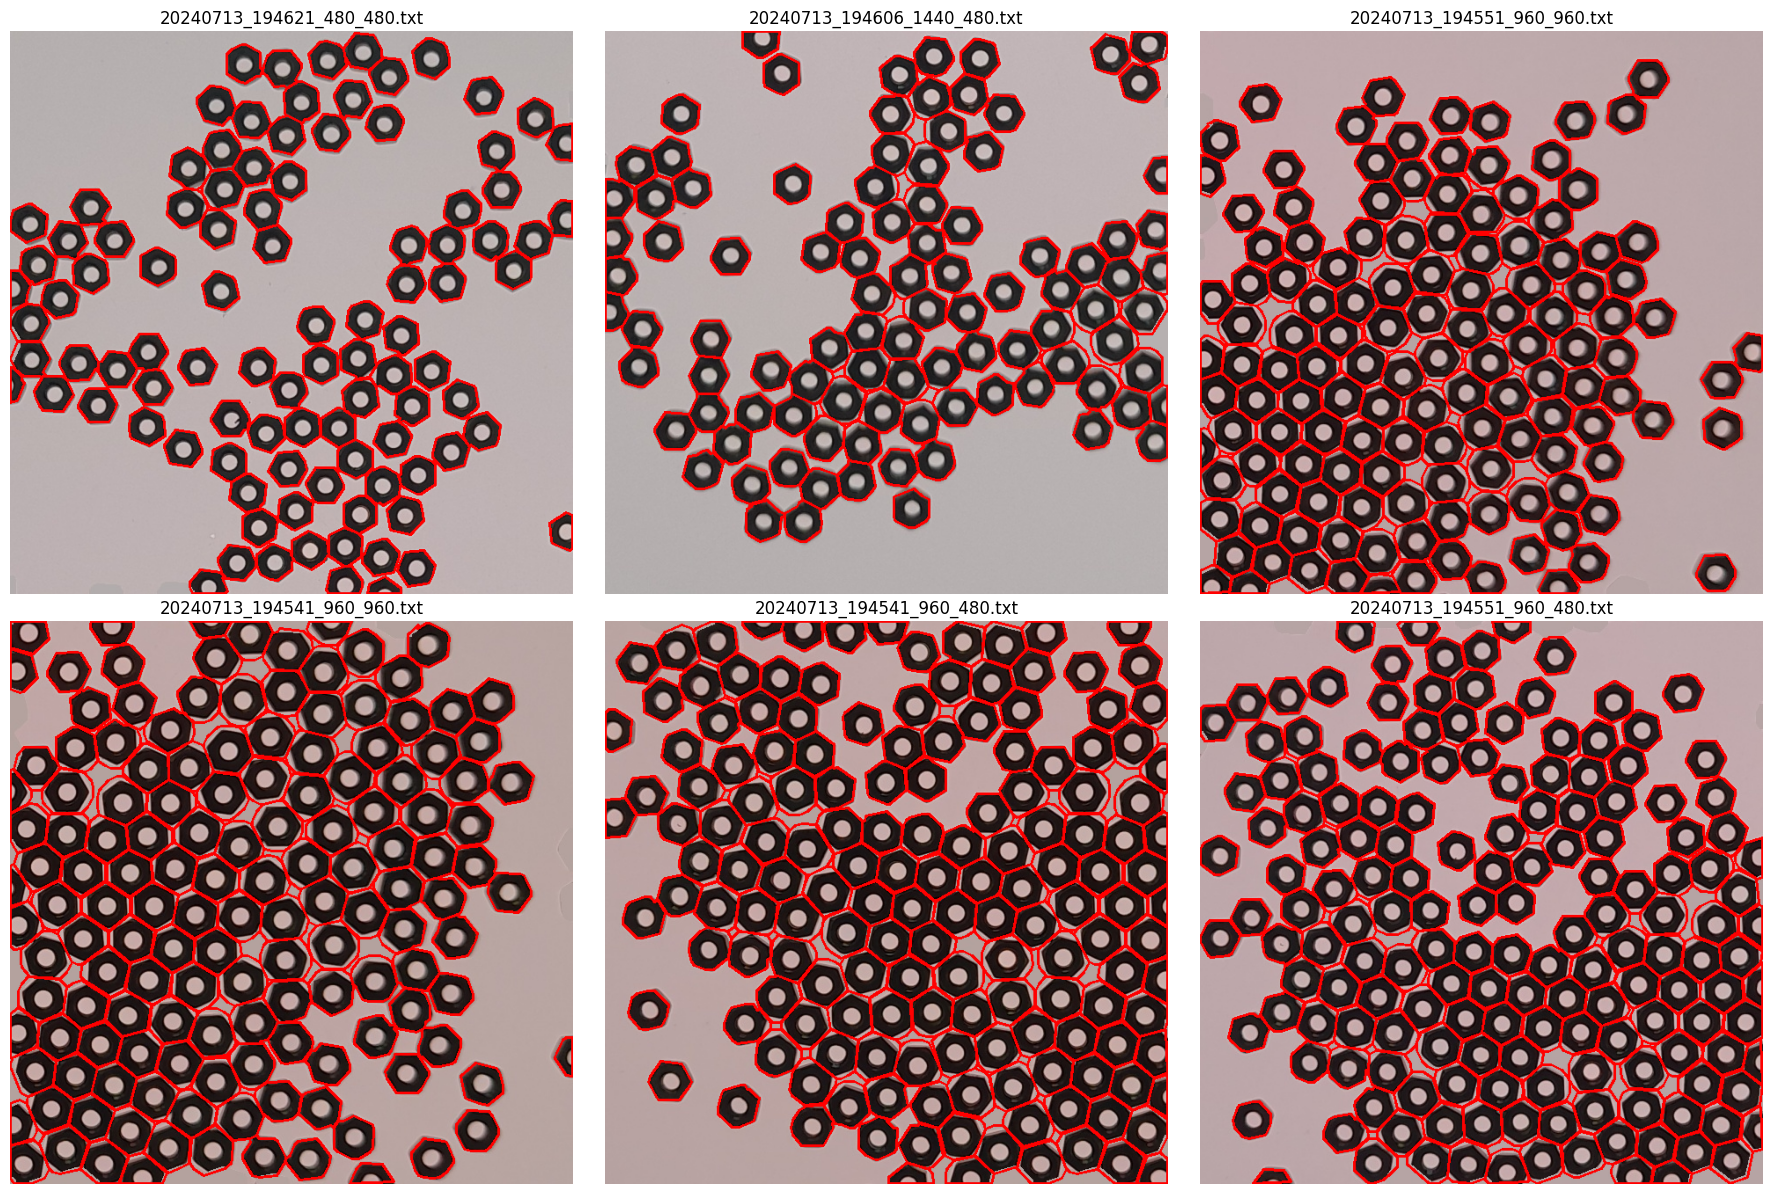

In [8]:
samples = sorted(glob.glob(os.path.join(DS_DIR, "labels", "train", "*.txt")), key=os.path.getsize)[-6:]
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, lp in zip(axes.ravel(), samples):
    img = cv2.imread(lp.replace("labels", "images").replace(".txt", ".jpg"))
    h, w = img.shape[:2]
    for line in open(lp).read().splitlines():
        pts = (np.array(line.split()[1:], float).reshape(-1, 2) * [w, h]).astype(np.int32)
        cv2.polylines(img, [pts], True, (0, 0, 255), 2)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(os.path.basename(lp))
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 2 — Fine-tune YOLO11s-seg
Single class `item`. Objects are photographed top-down, so vertical flips and rotations are valid augmentations. Mosaic and copy-paste are disabled: the nut tiles already hold 100+ instances each, and combining four of them per sample exhausted the memory of a 4 GB GPU without improving validation mAP.

In [9]:
model = YOLO(BASE_MODEL)
model.train(
    data=os.path.join(DS_DIR, "data.yaml"),
    epochs=EPOCHS,
    imgsz=TILE,
    batch=BATCH,
    device=0 if ON_GPU else "cpu",
    workers=0 if os.name == "nt" else 2,
    seed=SEED,
    deterministic=True,
    patience=25,
    flipud=0.5,
    fliplr=0.5,
    degrees=90,
    mosaic=0.0,
    copy_paste=0.0,
    hsv_h=0.02,
    hsv_s=0.5,
    hsv_v=0.4,
    project=WORK_DIR,
    name="train",
    exist_ok=True,
    plots=True,
    verbose=False,
)
BEST = os.path.join(WORK_DIR, "train", "weights", "best.pt")
shutil.copy(BEST, os.path.join(WORK_DIR, "best.pt"))
print("best weights:", BEST)

New https://pypi.org/project/ultralytics/8.4.218 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.253  Python-3.8.3 torch-2.4.1+cu118 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=work\dataset\data.yaml, degrees=90, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.02, hsv_s=0.5, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s-seg.pt, momentum=0.937, mosaic=0.0, multi_scale=False, name=train, nbs=64, nms=False, opset=Non

## Step 3 — Tiled inference and counting
Detections touching an inner tile edge are discarded because the 160 px overlap (larger than any item) guarantees the same item is complete in a neighbouring tile. Remaining duplicates from overlapping tiles are removed greedily by mask overlap (> 50 % of the smaller mask).

In [10]:
model = YOLO(BEST)
EDGE = 3
CONF = 0.25


def dedupe(dets, overlap_thr=0.5):
    dets = sorted(dets, key=lambda d: -d[0])
    boxes = np.array([d[4] for d in dets]).reshape(-1, 4).round().astype(int)
    areas = np.array([d[3].sum() for d in dets])
    keep_idx, dead = [], np.zeros(len(dets), bool)
    for i in range(len(dets)):
        if dead[i]:
            continue
        keep_idx.append(i)
        ix1 = np.maximum(boxes[i, 0], boxes[:, 0]); iy1 = np.maximum(boxes[i, 1], boxes[:, 1])
        ix2 = np.minimum(boxes[i, 2], boxes[:, 2]); iy2 = np.minimum(boxes[i, 3], boxes[:, 3])
        for j in np.nonzero((ix2 > ix1) & (iy2 > iy1) & ~dead)[0]:
            if j <= i:
                continue
            ci, yi, xi, mi, _ = dets[i]
            cj, yj, xj, mj, _ = dets[j]
            a = mi[iy1[j] - yi:iy2[j] - yi, ix1[j] - xi:ix2[j] - xi]
            b = mj[iy1[j] - yj:iy2[j] - yj, ix1[j] - xj:ix2[j] - xj]
            inter = (a & b).sum()
            if inter > overlap_thr * max(1, min(areas[i], areas[j])):
                dead[j] = True
    return [dets[i] for i in keep_idx]


def predict_image(bgr, conf=CONF):
    H, W = bgr.shape[:2]
    label_map = np.zeros((H, W), np.int32)
    ys, xs = tile_origins(H), tile_origins(W)
    origins = [(y0, x0) for y0 in ys for x0 in xs]
    tiles = [bgr[y0:y0 + TILE, x0:x0 + TILE] for y0, x0 in origins]
    results = []
    for i in range(0, len(tiles), 4):
        results += model.predict(tiles[i:i + 4], imgsz=TILE, conf=conf, iou=0.7, max_det=600,
                                 retina_masks=True, verbose=False, device=0 if ON_GPU else "cpu")
    dets = []
    for (y0, x0), r in zip(origins, results):
        if r.masks is None:
            continue
        th, tw = r.orig_shape
        boxes = r.boxes.xyxy.cpu().numpy()
        confs = r.boxes.conf.cpu().numpy()
        masks = r.masks.data.cpu().numpy() > 0.5
        for b, c, m in zip(boxes, confs, masks):
            cut = ((b[0] < EDGE and x0 > 0) or (b[1] < EDGE and y0 > 0)
                   or (b[2] > tw - EDGE and x0 + tw < W) or (b[3] > th - EDGE and y0 + th < H))
            if not cut:
                dets.append((c, y0, x0, m[:th, :tw], b + [x0, y0, x0, y0]))
    dets = dedupe(dets)
    for k, (c, y0, x0, m, _) in enumerate(sorted(dets, key=lambda d: d[0])):
        region = label_map[y0:y0 + m.shape[0], x0:x0 + m.shape[1]]
        region[m] = k + 1
    return len(dets), label_map


def draw_label_map(bgr, label_map, count, seed=SEED):
    rng = np.random.default_rng(seed)
    palette = rng.integers(60, 255, (label_map.max() + 1, 3)).astype(np.uint8)
    on = label_map > 0
    vis = bgr.copy()
    vis[on] = (0.45 * bgr[on] + 0.55 * palette[label_map[on]]).astype(np.uint8)
    edges = cv2.morphologyEx(label_map.astype(np.float32), cv2.MORPH_GRADIENT, np.ones((3, 3))) > 0
    vis[edges] = 0
    text = f"Count: {count}"
    cv2.rectangle(vis, (10, 10), (30 + 34 * len(text), 90), (255, 255, 255), -1)
    cv2.putText(vis, text, (20, 75), cv2.FONT_HERSHEY_SIMPLEX, 2.2, (0, 0, 255), 5)
    return vis


rows = []
t0 = time.time()
for path in IMAGES:
    name = os.path.relpath(path, DATA_DIR).replace(os.sep, "/")
    im = load_image(path)
    count, label_map = predict_image(im)
    cv2.imwrite(os.path.join(OUT_DIR, name.replace("/", "__")), draw_label_map(im, label_map, count))
    split = "test" if stem(path) in TEST_IMAGES else "train"
    rows.append({"image": name, "split": split, "predicted": count})
    print(f"{name:45s} {count:4d}  ({split})")

counts = pd.DataFrame(rows)
counts.to_csv(os.path.join(OUT_DIR, "counts.csv"), index=False)
print(f"\n{len(rows)} images in {time.time() - t0:.0f}s -> {OUT_DIR}/")

ScrewAndBolt_20240713/20240713_192951.jpg       21  (train)


ScrewAndBolt_20240713/20240713_193135.jpg       21  (test)


ScrewAndBolt_20240713/20240713_193650.jpg       10  (train)


ScrewAndBolt_20240713/20240713_193659.jpg       10  (test)


ScrewAndBolt_20240713/20240713_193831.jpg      182  (train)


ScrewAndBolt_20240713/20240713_193839.jpg      177  (train)


... (16 outputs left out)

Screws_2024_07_15/img4.jpg                      45  (train)


Screws_2024_07_15/img5.jpg                      45  (train)


Screws_2024_07_15/img6.jpg                      43  (test)



25 images in 32s -> work\outputs/


## Accuracy
Per-image accuracy = `1 - |predicted - true| / true`, using the manually verified counts in `ground_truth.csv`. The **test** rows are the held-out images the model never saw.

In [11]:
if GT_CSV:
    gt = pd.read_csv(GT_CSV).dropna(subset=["true_count"])
    res = counts.merge(gt[["image", "true_count"]], on="image")
    res["accuracy_%"] = (100 * (1 - (res.predicted - res.true_count).abs() / res.true_count)).round(2)
    display(res)
    for split, part in [("held-out test", res[res.split == "test"]), ("all", res)]:
        if len(part):
            overall = 100 * (1 - (part.predicted - part.true_count).abs().sum() / part.true_count.sum())
            print(f"{split:14s} mean accuracy {part['accuracy_%'].mean():6.2f}%  overall {overall:6.2f}%  "
                  f"exact {(part.predicted == part.true_count).sum()}/{len(part)}")
else:
    display(counts)

,image,split,predicted,true_count,accuracy_%
0,ScrewAndBolt_20240713/20240713_192951.jpg,train,21,21.0,100.00
1,ScrewAndBolt_20240713/20240713_193135.jpg,test,21,21.0,100.00
2,ScrewAndBolt_20240713/20240713_193650.jpg,train,10,10.0,100.00
3,ScrewAndBolt_20240713/20240713_193659.jpg,test,10,10.0,100.00
4,ScrewAndBolt_20240713/20240713_193907.jpg,test,184,195.0,94.36
5,ScrewAndBolt_20240713/20240713_194316.jpg,test,85,98.0,86.73
6,ScrewAndBolt_20240713/20240713_194630.jpg,test,354,354.0,100.00
7,Screws_2024_07_15/img1.jpg,train,43,43.0,100.00
8,Screws_2024_07_15/img1_43_nosy.jpg,train,43,43.0,100.00
9,Screws_2024_07_15/img2.jpg,train,43,43.0,100.00


held-out test  mean accuracy  96.85%  overall  96.67%  exact 4/6
all            mean accuracy  97.98%  overall  97.23%  exact 10/14


## Visual results (held-out test images)

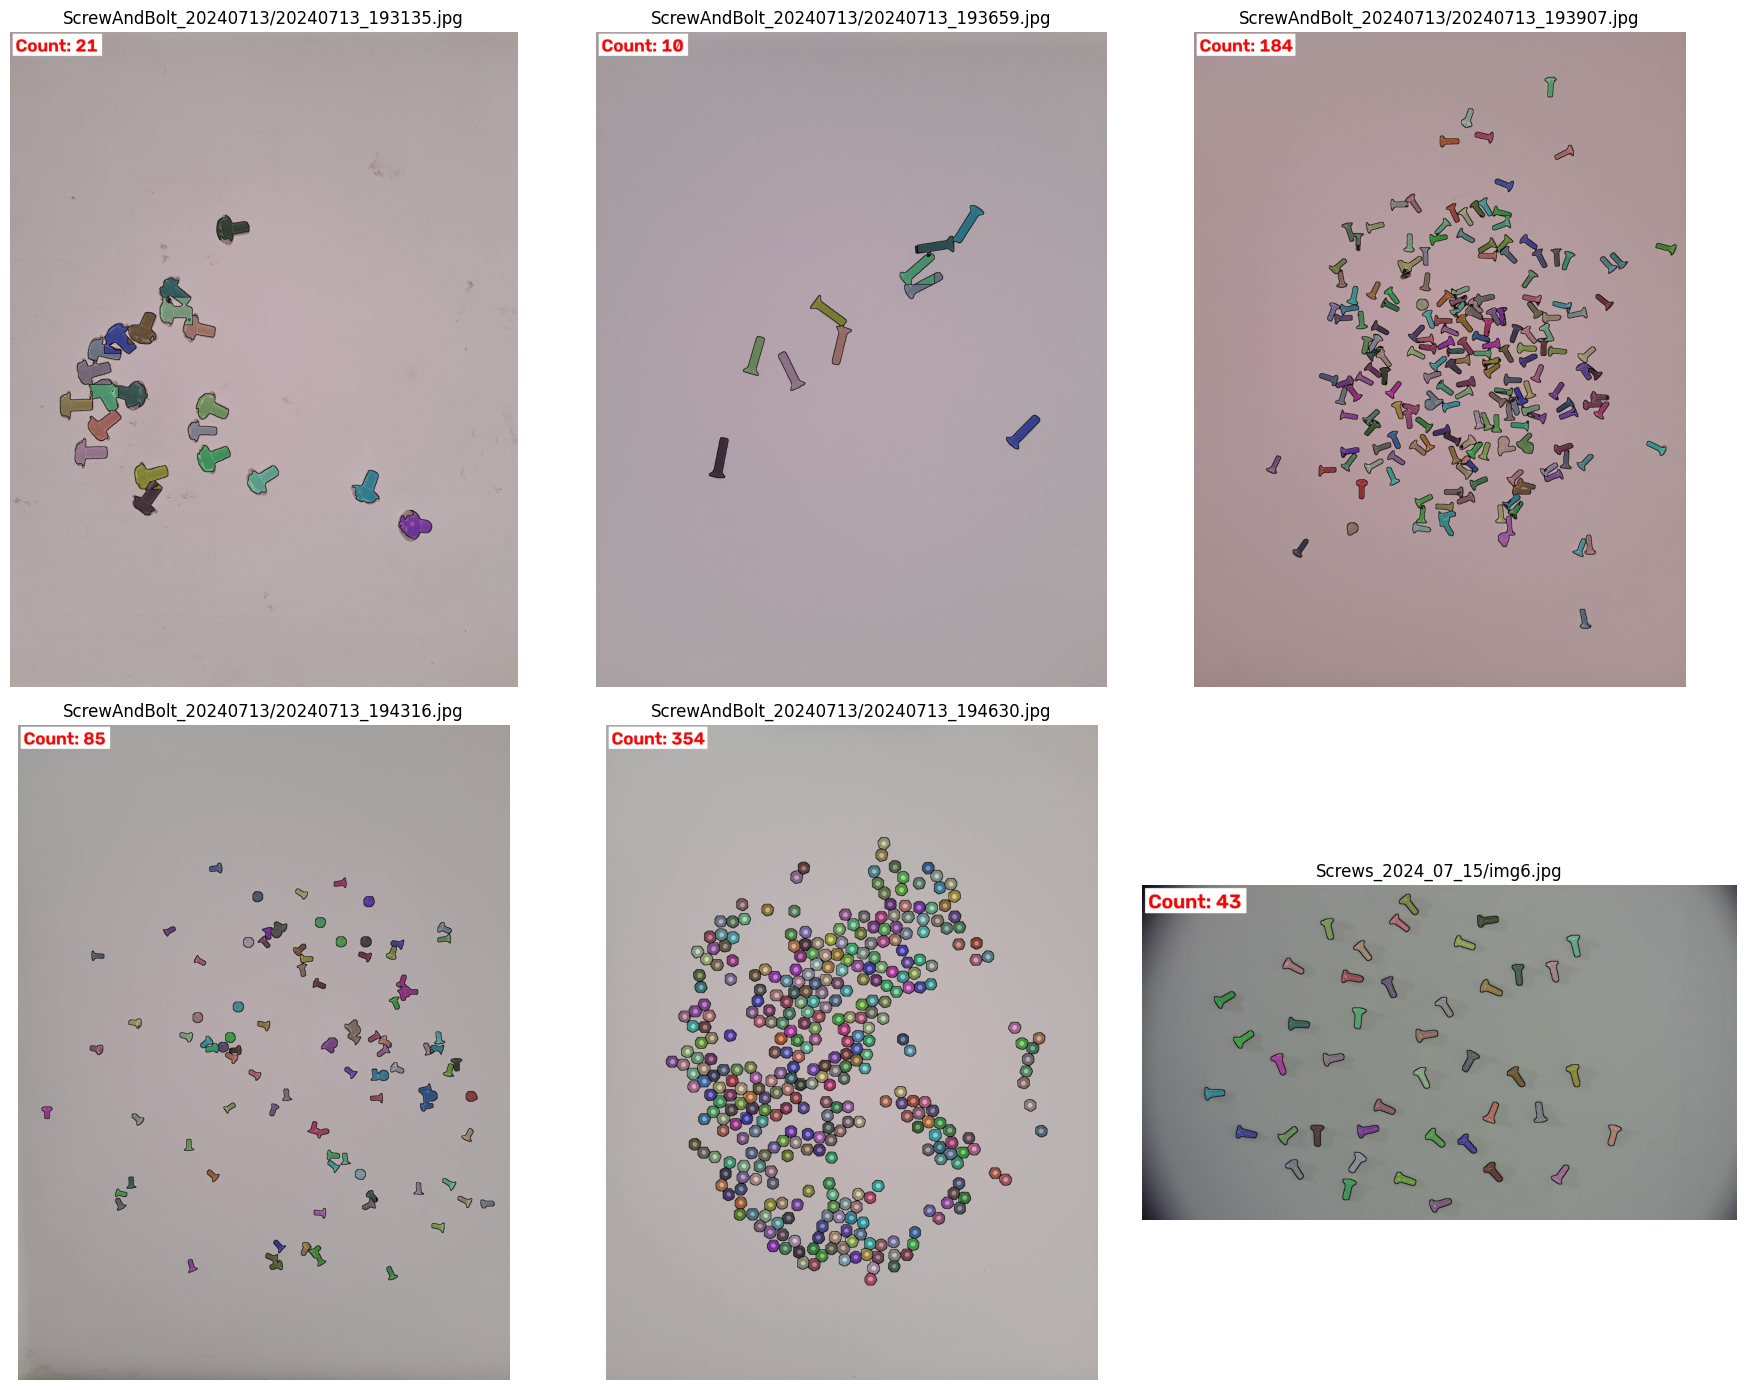

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(18, 14))
for ax in axes.ravel():
    ax.axis("off")
for ax, path in zip(axes.ravel(), TEST):
    name = os.path.relpath(path, DATA_DIR).replace(os.sep, "/")
    ax.imshow(cv2.cvtColor(cv2.imread(os.path.join(OUT_DIR, name.replace("/", "__"))), cv2.COLOR_BGR2RGB))
    ax.set_title(name)
plt.tight_layout()
plt.show()

## Training method (summary)
* **Base model:** `yolo11s-seg.pt` — Ultralytics YOLO11-small instance segmentation pretrained on COCO (generic objects, no screws/nuts).
* **Labels:** automatic pseudo-labels from the classical CV pipeline, confident instances only; uncertain regions painted with background colour. No manual polygon drawing.
* **Data:** training images scaled to 2400 px long side, cut into 640×640 tiles (stride 480); 85 % / 15 % train/val split by tile. Held-out images: `193135, 193659, 193907, 194316, 194630, img6` (one per object group).
* **Hyper-parameters:** 40 epochs, imgsz 640, batch 16 on a T4 (batch 2 on the 4 GB GTX 1650 used for the submitted run; Ultralytics accumulates gradients to a nominal batch of 64 either way), optimizer auto (AdamW), seed 0, deterministic, early stopping patience 25.
* **Augmentation:** horizontal + vertical flips, ±90° rotation, scale/translate, HSV jitter (mosaic and copy-paste off).
* **Hardware:** NVIDIA GTX 1650 4 GB (also runs unchanged on a Kaggle/Colab T4).
* **Inference:** 640 tiles with 160 px overlap, confidence 0.25, edge-cut detections dropped, mask-overlap de-duplication, masks merged into one label map.